# Figure 3 — Q2: with the truth in hand, what did the methods actually do?

Mock communities and simulations both carry a known answer. This figure asks what was removed, what was kept, and whether the proxy metrics of Figure 2 track any of it.

**Each panel is defined and drawn in its own cell.** Edit the function, re-run that one cell, see the result. The last cell assembles all of them at the submission size (180 x 225 mm) and writes the PDF that goes to the journal.

Run the Setup, Shared helpers and Data cells first; after that the panel cells are independent of each other.

## Setup

In [1]:
# Everything the panels read is relative to benchmark/, so make that the working directory
# whether the notebook was opened from benchmark/ or from benchmark/figures/.
if (basename(getwd()) == "figures") setwd("..")
stopifnot("run this from benchmark/ or benchmark/figures/" = file.exists("config/methods.tsv"))

# _panels.R holds what every figure shares: the method inventory and its ordering, the metric
# catalogue, the two normalisations used for ranking, the theme, and save_figure().
source("figures/_panels.R")

results_dir <- "results"

## Shared helpers

Small pieces more than one panel below needs.

In [2]:
# Short enough to survive a quarter-width facet strip.
short_dataset <- function(paths)
  factor(c(brooks = "brooks", jmbc_extraction = "JMBC extr", jmbc_library = "JMBC libr",
           salim_pig = "salim pig")[sub(".*/", "", paths)],
         c("brooks", "JMBC extr", "JMBC libr", "salim pig"))

# Each method's value minus the value `raw` got on the same dataset: the improvement correction bought.
change_from_raw <- function(scored, metric) {
  reference <- scored[scored$method == "raw", c("dataset", metric)]
  names(reference)[2] <- "raw_value"
  joined <- inner_join(scored[scored$method != "raw", c("dataset", "method", "scenario", metric)],
                       reference, by = "dataset")
  joined$change <- joined[[metric]] - joined$raw_value
  joined
}

## Data

In [3]:
scored <- read_scores(file.path(results_dir, "scores.tsv"))
simulated <- scored[scored$regime == "sim" & scored$status == "ok" & scored$method != "oracle", ]
truth_summary <- read.delim(file.path(results_dir, "truth_summary.tsv"))
truth_summary <- truth_summary[!is.na(truth_summary$aitchison_to_truth), ]
per_taxon <- read.delim(file.path(results_dir, "truth_taxon.tsv"))

cat(nrow(simulated), "simulated rows,", nrow(truth_summary), "known-composition rows\n")

18054 simulated rows, 38 known-composition rows


## a. Per-taxon bias against the pipetted truth

Taxa ordered by their bias before correction. Genus names abbreviated and italicised; spelled out they cost a quarter of the figure's height.

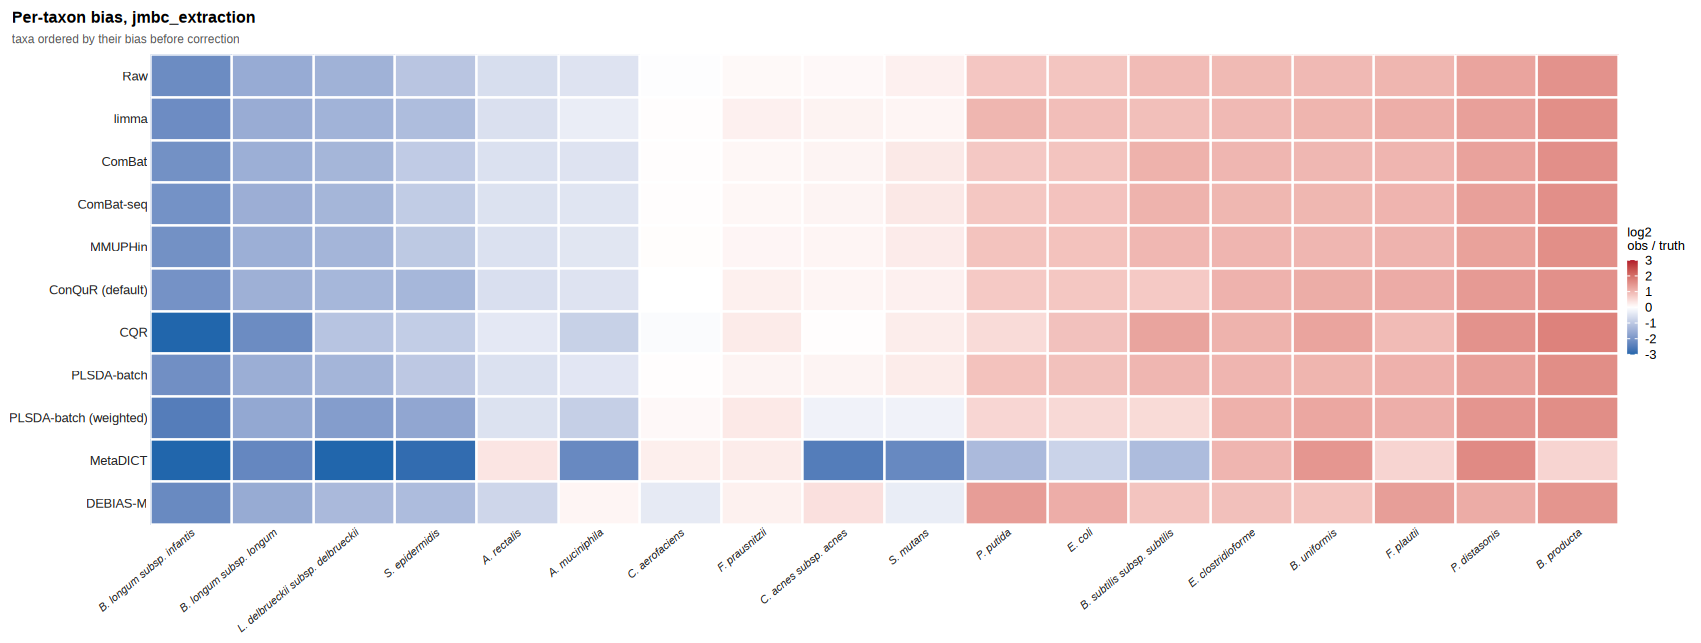

In [4]:
panel_taxon_bias <- function(per_taxon, dataset, methods_table = method_table()) {
  shown <- per_taxon[per_taxon$dataset == dataset & !is.na(per_taxon$log2_ratio), ]
  # "Bifidobacterium longum subsp. infantis" spelled out costs a quarter of the figure's height, and
  # the genus is never ambiguous inside one mock community.
  shown$taxon <- sub("^([A-Z])[a-z]+ ", "\\1. ", shown$taxon)
  shown$taxon <- factor(shown$taxon, unique(shown$taxon[order(shown$log2_ratio[shown$method == "raw"])]))
  ggplot(label_methods(shown, methods_table), aes(taxon, label, fill = log2_ratio)) +
    geom_tile(colour = "white", linewidth = 0.4) +
    scale_fill_diverging(c(-3, 3), name = "log2\nobs / truth", guide = slim_bar()) +
    scale_x_discrete(expand = expansion(0)) +
    scale_y_discrete(limits = rev, expand = expansion(0)) +
    labs(x = NULL, y = NULL, title = paste("Per-taxon bias,", sub(".*/", "", dataset)),
         subtitle = "taxa ordered by their bias before correction") +
    theme_bench() + theme_tiles() +
    theme(axis.text.x = element_text(angle = 40, hjust = 1, size = 5, face = "italic"))
}

show_panel(panel_taxon_bias(per_taxon, "real/jmbc_extraction"), 180, 68)

## b. Accuracy against the pipetted truth

Aitchison distance to the known composition, per mock dataset. A missing bar is a method that returned no result there.

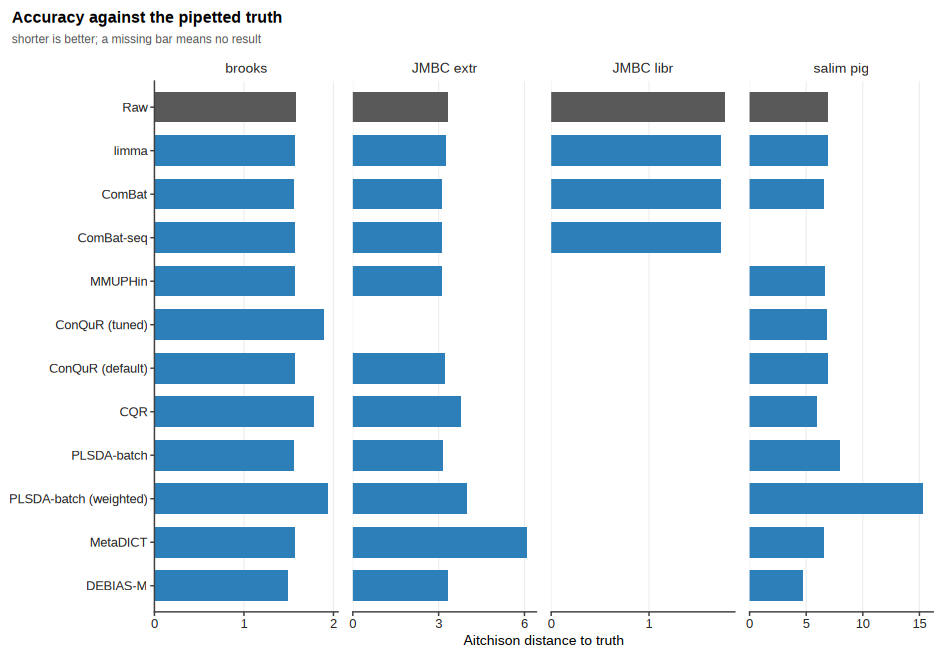

In [5]:
panel_distance_to_truth <- function(truth_summary, methods_table = method_table()) {
  shown <- label_methods(truth_summary, methods_table)
  shown$dataset <- short_dataset(shown$dataset)
  ggplot(shown, aes(aitchison_to_truth, label, fill = track)) +
    geom_col(width = 0.68) +
    facet_wrap(~ dataset, nrow = 1, scales = "free_x") +
    scale_fill_manual(values = track_colours(), guide = "none") +
    scale_y_discrete(limits = rev) +
    scale_x_continuous(n.breaks = 3, expand = expansion(mult = c(0, 0.06))) +
    labs(x = "Aitchison distance to truth", y = NULL, title = "Accuracy against the pipetted truth",
         subtitle = "shorter is better; a missing bar means no result") +
    theme_bench() + theme(panel.grid.major.y = element_blank())
}

show_panel(panel_distance_to_truth(truth_summary), 100, 70)

## c. False structure between protocols

Identical material, many protocols: whatever batch variance survives is spurious by construction.

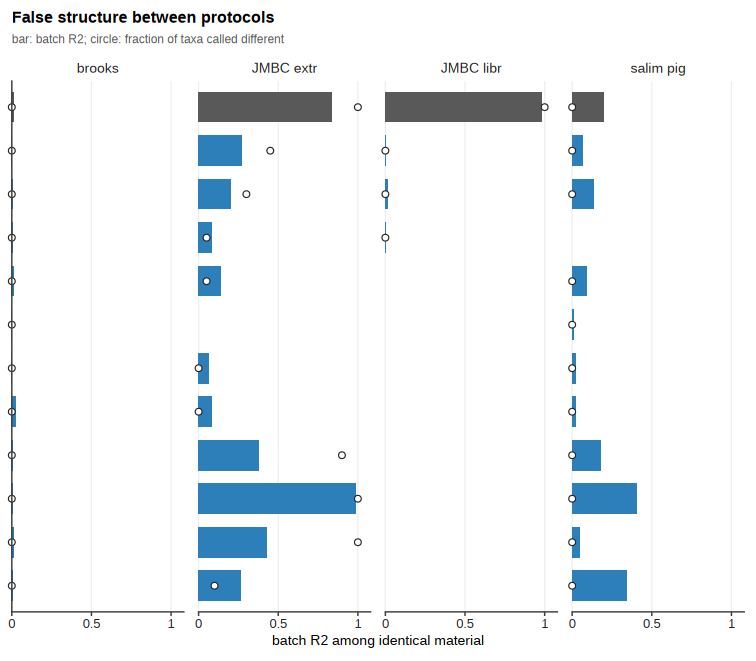

In [6]:
panel_false_structure <- function(truth_summary, methods_table = method_table()) {
  shown <- label_methods(truth_summary, methods_table)
  shown$dataset <- short_dataset(shown$dataset)
  shown$false_da_fraction <- shown$false_da_n / shown$n_taxa
  ggplot(shown, aes(y = label)) +
    geom_col(aes(x = R2_batch, fill = track), width = 0.68) +
    geom_point(aes(x = false_da_fraction), shape = 21, fill = "white", colour = "grey15",
               size = 1.1, stroke = 0.3) +
    facet_wrap(~ dataset, nrow = 1) +
    coord_cartesian(clip = "off") +   # the circles at zero sit on the axis and would be cut in half
    scale_fill_manual(values = track_colours(), guide = "none") +
    scale_y_discrete(limits = rev) +
    scale_x_continuous(breaks = c(0, 0.5, 1), labels = c("0", "0.5", "1"),
                       expand = expansion(mult = c(0, 0.08))) +
    labs(x = "batch R2 among identical material", y = NULL,
         title = "False structure between protocols",
         subtitle = "bar: batch R2; circle: fraction of taxa called different") +
    theme_bench() +
    theme(axis.text.y = element_blank(), axis.ticks.y = element_blank(),
          panel.grid.major.y = element_blank())
}

show_panel(panel_false_structure(truth_summary), 80, 70)

## d. Fidelity to the simulated truth

Agreement with the batch-free oracle table, as distance fidelity and as per-taxon fidelity.

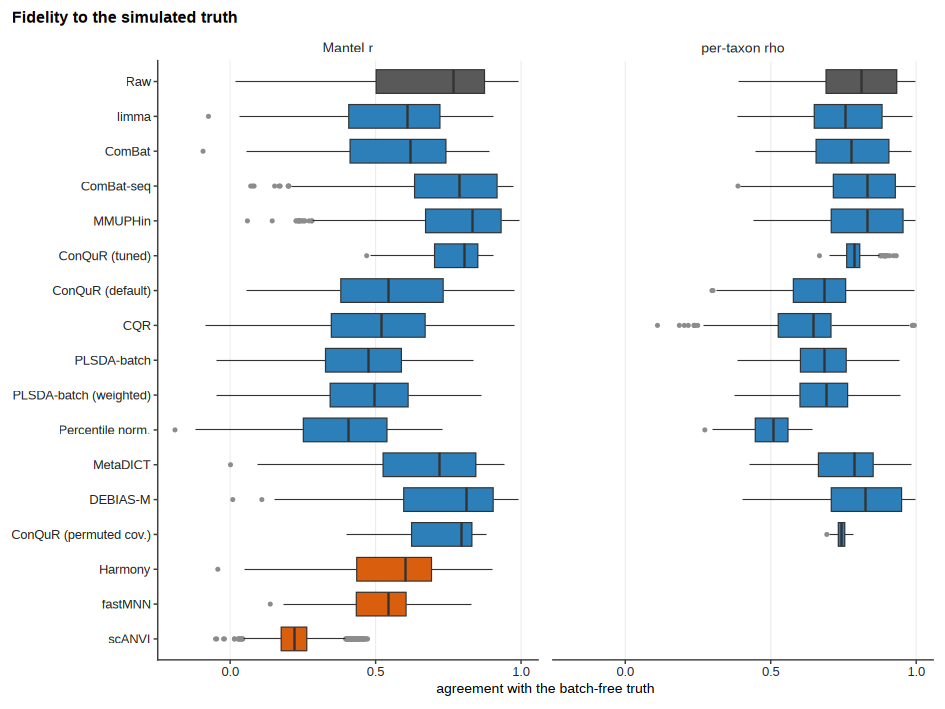

In [7]:
panel_oracle_fidelity <- function(simulated, methods_table = method_table()) {
  long <- bind_rows(
    data.frame(method = simulated$method, value = simulated$oracle_mantel, measure = "Mantel r"),
    data.frame(method = simulated$method, value = simulated$oracle_taxon_rho, measure = "per-taxon rho"))
  ggplot(label_methods(long[!is.na(long$value), ], methods_table), aes(value, label, fill = track)) +
    geom_boxplot(outlier.size = 0.15, outlier.colour = "grey55", linewidth = 0.2, width = 0.68,
                 colour = "grey20") +
    facet_wrap(~ measure, nrow = 1) +
    scale_fill_manual(values = track_colours(), guide = "none") +
    scale_y_discrete(limits = rev) + scale_x_continuous(n.breaks = 3) +
    labs(x = "agreement with the batch-free truth", y = NULL,
         title = "Fidelity to the simulated truth") +
    theme_bench() + theme(panel.grid.major.y = element_blank())
}

show_panel(panel_oracle_fidelity(simulated), 100, 75)

## e. Does the multiplicative assumption decide it?

Median per-taxon fidelity, one dot per share of the community the bias touched. A method built on a systematic multiplicative bias should do best where the dark dot is.

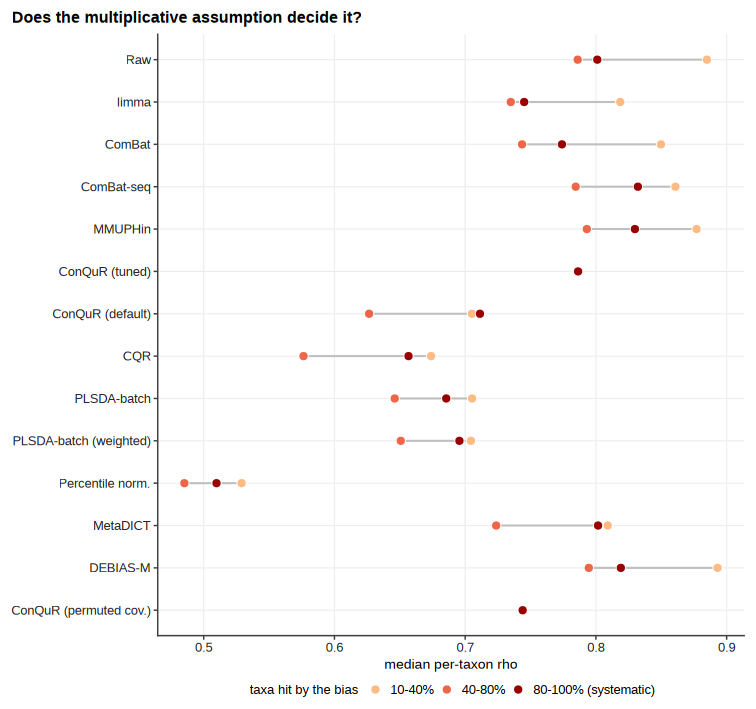

In [8]:
panel_systematic <- function(simulated, methods_table = method_table()) {
  shown <- simulated[!is.na(simulated$oracle_taxon_rho), ]
  shown$bias_kind <- cut(shown$affected, c(0, 0.4, 0.8, 1),
                         labels = c("10-40%", "40-80%", "80-100% (systematic)"))
  medians <- shown %>% group_by(method, bias_kind) %>%
    summarise(rho = median(oracle_taxon_rho), .groups = "drop")
  ggplot(label_methods(medians, methods_table), aes(rho, label)) +
    geom_line(aes(group = label), colour = "grey75", linewidth = 0.35) +
    geom_point(aes(fill = bias_kind), shape = 21, colour = "white", stroke = 0.25, size = 1.7) +
    scale_fill_manual(values = level_colours(), name = "taxa hit by the bias") +
    scale_y_discrete(limits = rev) +
    labs(x = "median per-taxon rho", y = NULL,
         title = "Does the multiplicative assumption decide it?") +
    theme_bench() + theme(legend.position = "bottom")
}

show_panel(panel_systematic(simulated), 80, 75)

## f. Proxy against truth

One point per scenario: batch variance removed against fidelity gained, both relative to raw. The lower-right quadrant is correction that removed batch and lost the truth with it.

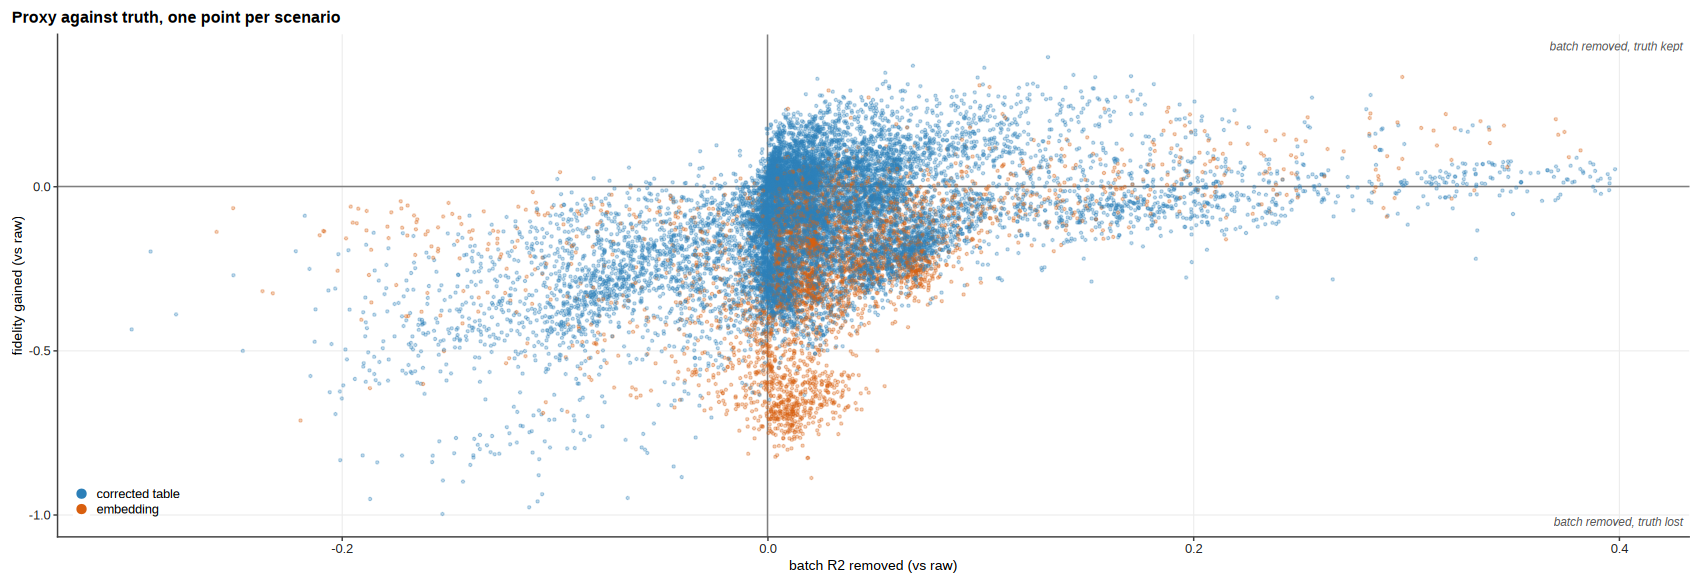

In [9]:
panel_proxy_versus_truth <- function(simulated, methods_table = method_table()) {
  batch <- change_from_raw(simulated, "R2_batch_ait")
  truth <- change_from_raw(simulated, "oracle_mantel")
  joined <- inner_join(batch %>% select(dataset, method, batch_change = change),
                       truth %>% select(dataset, method, truth_change = change),
                       by = c("dataset", "method"))
  # shuffled, so the smaller embedding group is not painted over by the corrected tables
  set.seed(1)
  joined <- label_methods(joined, methods_table)[sample.int(nrow(joined)), ]
  corners <- data.frame(x = c(Inf, Inf), y = c(Inf, -Inf), hjust = 1.05, vjust = c(1.8, -1.2),
                        label = c("batch removed, truth kept", "batch removed, truth lost"))
  ggplot(joined, aes(-batch_change, truth_change)) +
    geom_hline(yintercept = 0, linewidth = 0.25, colour = "grey50") +
    geom_vline(xintercept = 0, linewidth = 0.25, colour = "grey50") +
    geom_point(aes(colour = track), size = 0.3, alpha = 0.3) +
    geom_text(data = corners, aes(x, y, label = label, hjust = hjust, vjust = vjust), size = 1.9,
              colour = "grey35", fontface = "italic") +
    scale_colour_manual(values = track_colours(), labels = track_labels(), name = NULL) +
    guides(colour = guide_legend(override.aes = list(size = 1.6, alpha = 1))) +
    labs(x = "batch R2 removed (vs raw)", y = "fidelity gained (vs raw)",
         title = "Proxy against truth, one point per scenario") +
    theme_bench() +
    theme(legend.position = "inside", legend.position.inside = c(0.01, 0.04),
          legend.justification = c(0, 0), legend.background = element_blank())
}

show_panel(panel_proxy_versus_truth(simulated), 180, 62)

## Assembled figure

Everything above, in the layout that goes to the journal: 180 x 225 mm, one page.
The panels shrink here — that is the real submission size, and the font sizes above were
chosen for it.

wrote results/figures/fig3.pdf (180 x 225 mm)


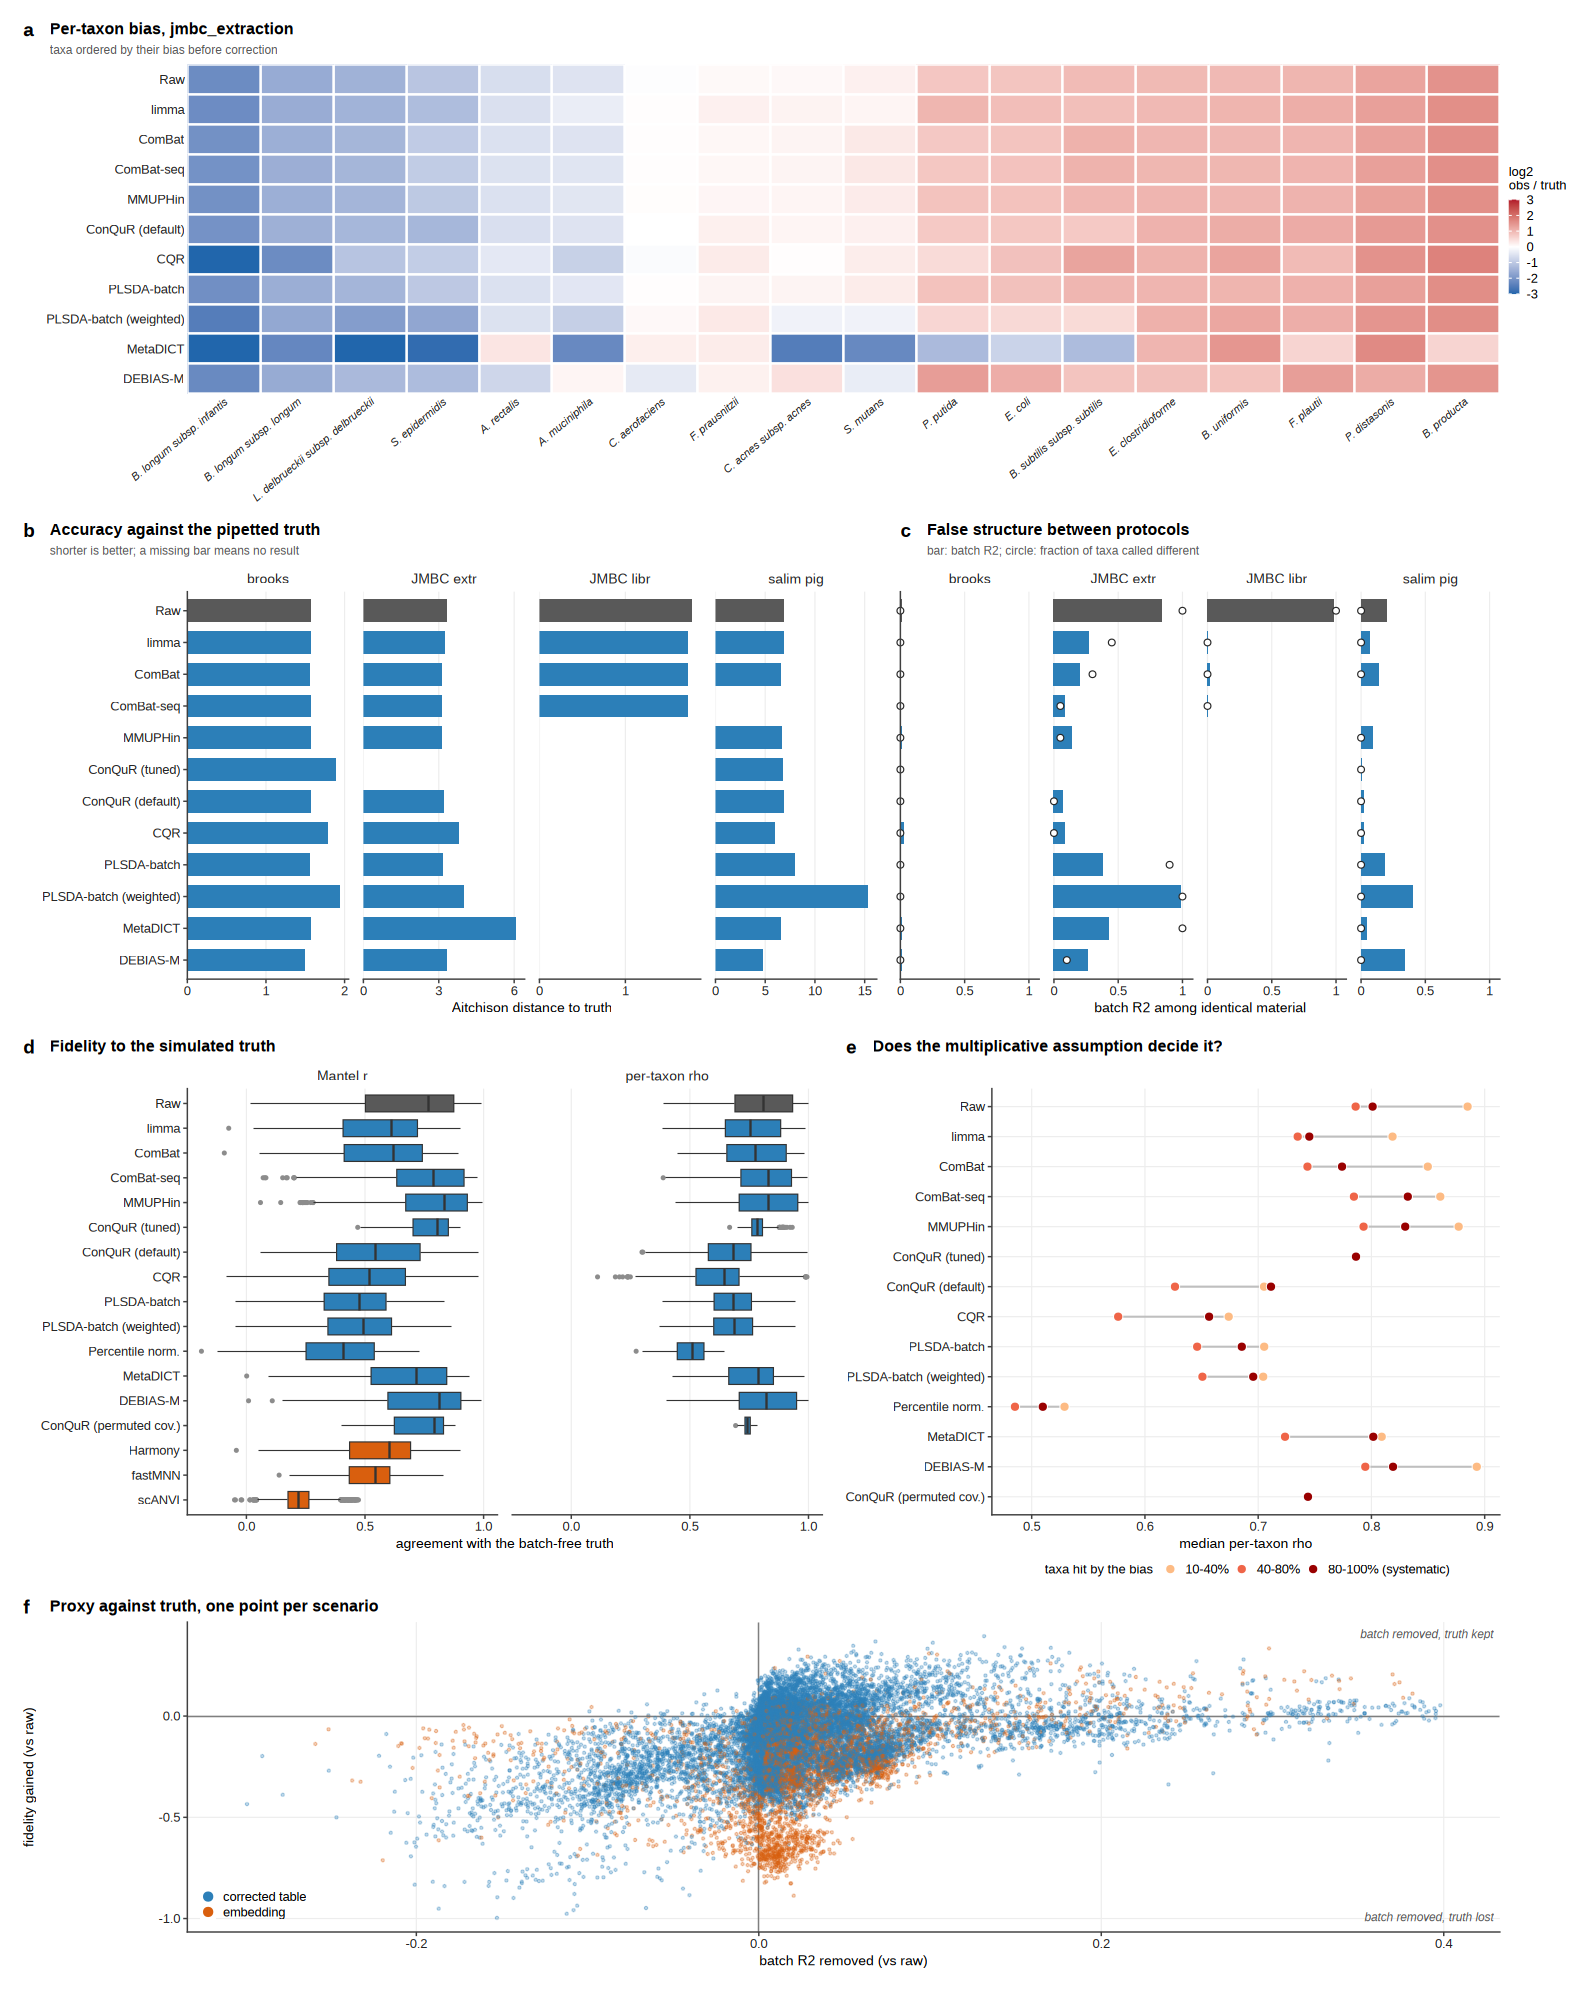

In [10]:
mock_row <- (panel_distance_to_truth(truth_summary) | panel_false_structure(truth_summary)) +
  plot_layout(widths = c(1.15, 1))
simulated_row <- (panel_oracle_fidelity(simulated) | panel_systematic(simulated)) +
  plot_layout(widths = c(1.25, 1))

figure <- assemble(panel_taxon_bias(per_taxon, "real/jmbc_extraction") / mock_row / simulated_row /
                   panel_proxy_versus_truth(simulated) + plot_layout(heights = c(0.85, 1, 1.1, 0.8)))

save_figure(figure, "results/figures/fig3.pdf", 180, 225)
show_panel(figure, 180, 225, scale = 1.5)